<a href="https://colab.research.google.com/github/shrutikushwaha2110-ux/Facial-Expression-Recognition-CNN/blob/main/notebooks/04_transfer_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import numpy as np

# Load the new leakage-checked archive directly
data = np.load("/content/fer2013_preprocessed_leakage_checked.npz.zip")

# Access the arrays directly from the loaded object
X_train = data["X_train"]
y_train = data["y_train"]
X_val = data["X_val"]
y_val = data["y_val"]
X_test = data["X_test_clean"]
y_test = data["y_test_clean"]

print("Successfully loaded clean data directly from NPZ!")
print(f"X_train shape: {X_train.shape}")
print(f"X_val shape:   {X_val.shape}")
print(f"X_test shape:  {X_test.shape}")  # Should show 6,611 samples

Successfully loaded clean data directly from NPZ!
X_train shape: (22949, 48, 48, 1)
X_val shape:   (5749, 48, 48, 1)
X_test shape:  (6611, 48, 48, 1)


Preparing and resizing train and validation datasets...
Batch Normalization layers successfully frozen for fine-tuning.
Starting fine-tuning with Early Stopping and Class Weights...
Epoch 1/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 29s 51ms/step - accuracy: 0.3034 - loss: 1.7723 - val_accuracy: 0.4368 - val_loss: 1.5137 - learning_rate: 1.0000e-04
Epoch 2/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.4178 - loss: 1.5160 - val_accuracy: 0.4171 - val_loss: 1.5298 - learning_rate: 1.0000e-04
Epoch 3/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.4700 - loss: 1.3685 - val_accuracy: 0.5105 - val_loss: 1.2926 - learning_rate: 1.0000e-04
Epoch 4/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.5092 - loss: 1.2490 - val_accuracy: 0.4799 - val_loss: 1.3601 - learning_rate: 1.0000e-04
Epoch 5/15
359/359 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.5375 - loss: 1.1519 - val_accuracy: 0.5304 - val_loss: 1.2462 - learning_rate: 1.0000e-04
Epoch 6/15
359/359 ━━━━━━━━━━━━━

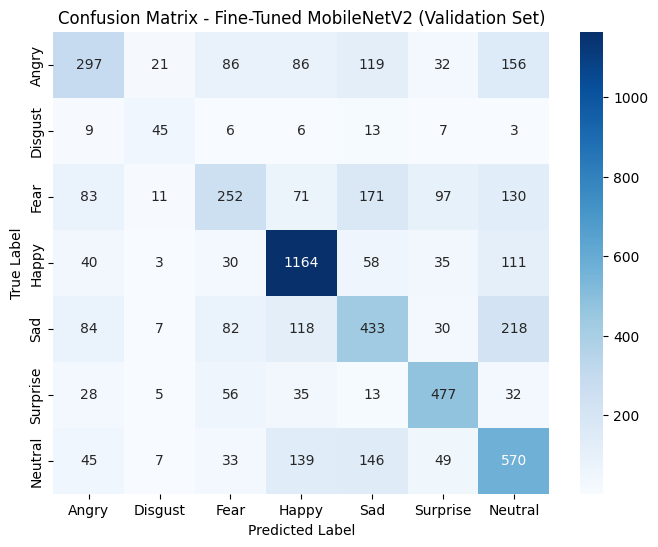

Validation confusion matrix saved to confusion_matrix_val.png


In [10]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam


# 1. Resize and prepare Train and Validation datasets only
def prepare_mb_data(X, batch_size=1000):
  processed_batches = []
  for i in range(0, len(X), batch_size):
    batch = X[i : i + batch_size]
    X_resized = tf.image.resize(batch, (96, 96))
    X_rgb = tf.repeat(X_resized, repeats=3, axis=-1)
    X_rgb = (X_rgb * 2.0) - 1.0
    processed_batches.append(X_rgb)
  return tf.concat(processed_batches, axis=0)


print('Preparing and resizing train and validation datasets...')
X_train_mb = prepare_mb_data(X_train)
X_val_mb = prepare_mb_data(X_val)

# Compute balanced class weights
class_weights = compute_class_weight(
    class_weight='balanced', classes=np.unique(y_train), y=y_train
)
class_weights_dict = dict(enumerate(class_weights))

# 2. Build MobileNetV2 with custom classification head
base_model = MobileNetV2(
    input_shape=(96, 96, 3), include_top=False, weights='imagenet'
)
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
output_layer = Dense(7, activation='softmax')(x)
model = Model(inputs=base_model.input, outputs=output_layer)

# 3. Unfreeze for Fine-Tuning (Top 20 layers, freeze BatchNorm)
base_model.trainable = True
for layer in base_model.layers[:-20]:
  layer.trainable = False

for layer in base_model.layers:
  if isinstance(layer, tf.keras.layers.BatchNormalization):
    layer.trainable = False

print('Batch Normalization layers successfully frozen for fine-tuning.')

# 4. Recompile with a low learning rate
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

# 5. Set up Callbacks
early_stopping = EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', factor=0.5, patience=2, min_lr=0.00001
)

print('Starting fine-tuning with Early Stopping and Class Weights...')

# 6. Train the fine-tuned model on Train and Validation data
history_fine = model.fit(
    X_train_mb,
    y_train,
    validation_data=(X_val_mb, y_val),
    epochs=15,
    batch_size=64,
    class_weight=class_weights_dict,
    callbacks=[early_stopping, reduce_lr],
)

# Save the trained model so your teammate can use it for test evaluation
model.save('/content/fer2013_mobilenet_finetuned_best.keras')
print(
    'Fine-tuned model saved successfully to'
    ' /content/fer2013_mobilenet_finetuned_best.keras!'
)

# 7. Evaluate on Validation Set (Macro Metrics, Classification Report, Confusion Matrix)
print('\n--- Validation Set Evaluation ---')
val_loss, val_accuracy = model.evaluate(X_val_mb, y_val, verbose=0)
y_val_pred_probs = model.predict(X_val_mb)
y_val_pred = np.argmax(y_val_pred_probs, axis=1)

val_macro_precision = precision_score(
    y_val, y_val_pred, average='macro', zero_division=0
)
val_macro_recall = recall_score(
    y_val, y_val_pred, average='macro', zero_division=0
)
val_macro_f1 = f1_score(y_val, y_val_pred, average='macro', zero_division=0)

print(f'Validation Loss:          {val_loss:.4f}')
print(f'Validation Accuracy:      {val_accuracy * 100:.2f}%')
print(f'Validation Macro Precision:{val_macro_precision:.4f}')
print(f'Validation Macro Recall:   {val_macro_recall:.4f}')
print(f'Validation Macro F1 Score: {val_macro_f1:.4f}')

# Classification Report & Save to file
emotion_labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Sad', 'Surprise', 'Neutral']
val_class_report_str = classification_report(
    y_val, y_val_pred, target_names=emotion_labels, zero_division=0
)
print('\nValidation Classification Report:\n', val_class_report_str)

with open('classification_report_val.txt', 'w') as f:
  f.write(val_class_report_str)
print('Validation classification report saved to classification_report_val.txt')

# Save and Plot Confusion Matrix for Validation Data
plt.figure(figsize=(8, 6))
cm_val = confusion_matrix(y_val, y_val_pred)
sns.heatmap(
    cm_val,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=emotion_labels,
    yticklabels=emotion_labels,
)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Fine-Tuned MobileNetV2 (Validation Set)')
plt.savefig('confusion_matrix_val.png', bbox_inches='tight')
plt.show()
print('Validation confusion matrix saved to confusion_matrix_val.png')